In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

locations = pd.read_csv("../data/locations.csv")

Matplotlib is building the font cache; this may take a moment.


In [2]:
aq = pd.read_csv("../data/air_quality_archive.csv", parse_dates=["date"])
crowd = pd.read_csv("../data/crowd_weekly.csv", parse_dates=["week_start"])

print(crowd["week_start"].dt.day_name().value_counts())

def to_week_start(dates):
    return dates - pd.to_timedelta((dates.dt.dayofweek + 1) % 7, unit="D")

w = pd.read_csv("../data/weather_archive.csv", parse_dates=["date"])
w["week_start"] = to_week_start(w["date"])
weekly_w = w.groupby(["location_id", "week_start"]).agg(
    rain_mm=("rainfall_mm", "sum"),
    temp_mean=("temp_mean", "mean"),
    temp_max=("temp_max", "max"),
    wind_max=("wind_max", "max"),
).reset_index()

aq["week_start"] = to_week_start(aq["date"])
weekly_aq = aq.groupby(["location_id", "week_start"]).agg(
    aqi_mean=("aqi_mean", "mean"),
    pm25=("pm25_mean", "mean"),
).reset_index()

panel = (
    crowd.drop(columns="id")
    .merge(weekly_w, on=["location_id", "week_start"])
    .merge(weekly_aq, on=["location_id", "week_start"])
    .merge(locations[["id", "name", "category"]], left_on="location_id", right_on="id")
    .drop(columns="id")
)
print(panel.shape)
panel.head()

week_start
Sunday    2088
Name: count, dtype: int64
(1752, 11)


,location_id,week_start,interest,rain_mm,temp_mean,temp_max,wind_max,aqi_mean,pm25,name,category
0,1,2022-07-31,39,656.9,16.914286,21.6,28.0,20.895833,3.624415,Munnar,hill_station
1,1,2022-08-07,47,241.6,16.471429,21.1,26.4,24.970238,4.483333,Munnar,hill_station
2,1,2022-08-14,41,27.1,17.985714,23.1,18.4,51.255952,10.717262,Munnar,hill_station
3,1,2022-08-21,40,175.3,16.942857,20.8,17.9,33.720238,5.906548,Munnar,hill_station
4,1,2022-08-28,33,119.6,17.685714,22.7,10.2,42.750000,7.802381,Munnar,hill_station


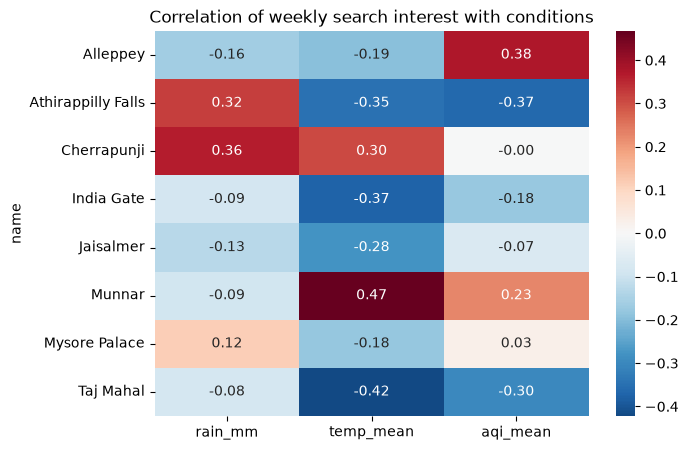

In [3]:
cols = ["interest", "rain_mm", "temp_mean", "aqi_mean"]
corr = (
    panel.groupby("name")[cols].corr()
    .xs("interest", level=1)
    .drop(columns="interest")
)

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation of weekly search interest with conditions")
plt.show()

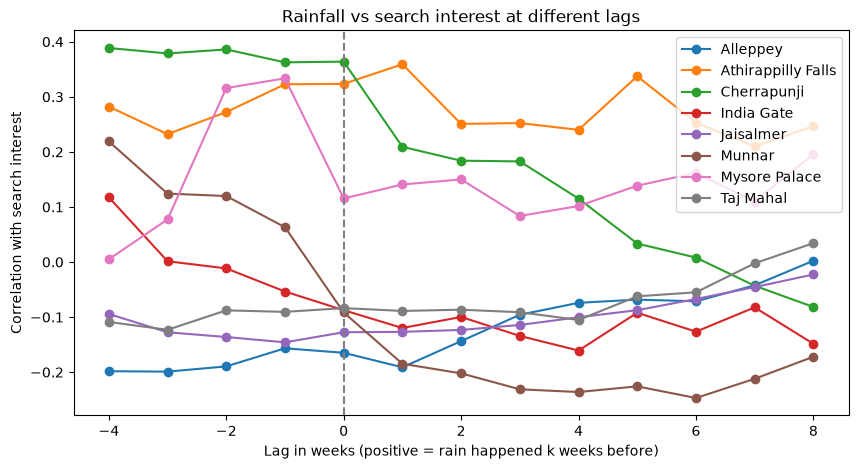

In [4]:
lags = range(-4, 9)
results = {}
for name, g in panel.groupby("name"):
    g = g.sort_values("week_start")
    results[name] = [g["interest"].corr(g["rain_mm"].shift(k)) for k in lags]

lag_df = pd.DataFrame(results, index=list(lags))
lag_df.plot(figsize=(10, 5), marker="o")
plt.axvline(0, color="grey", linestyle="--")
plt.xlabel("Lag in weeks (positive = rain happened k weeks before)")
plt.ylabel("Correlation with search interest")
plt.title("Rainfall vs search interest at different lags")
plt.show()

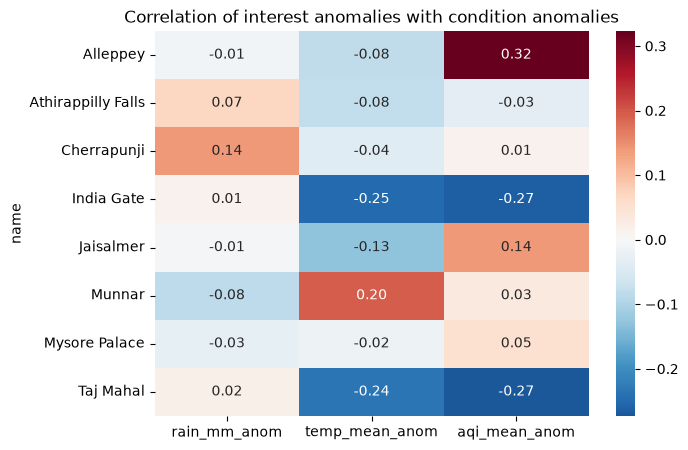

In [5]:
panel["month"] = panel["week_start"].dt.month

for c in ["interest", "rain_mm", "temp_mean", "aqi_mean"]:
    panel[c + "_anom"] = panel[c] - panel.groupby(["name", "month"])[c].transform("mean")

anom_cols = ["interest_anom", "rain_mm_anom", "temp_mean_anom", "aqi_mean_anom"]
corr_anom = (
    panel.groupby("name")[anom_cols].corr()
    .xs("interest_anom", level=1)
    .drop(columns="interest_anom")
)

plt.figure(figsize=(7, 5))
sns.heatmap(corr_anom, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation of interest anomalies with condition anomalies")
plt.show()